In [1]:
from pathlib import Path
from collections import OrderedDict
from importlib.metadata import version
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence
from IPython.display import display, Image
from split_policy import assign_household_split, SPLIT_SEED, TEST_FRACTION

BASE_DIR = Path.cwd()
WORKBOOK = BASE_DIR / 'inputs' / 'households.xlsx'
SHEET = '2006-hhld'
WORK = BASE_DIR / 'intermediaries' / 'MLR_regression'
OUTPUT = BASE_DIR / 'final_outputs' / 'MLR_regression'
FIGURES = OUTPUT / 'figures'
for folder in [WORK, OUTPUT, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

ALPHA = 0.01
HIGH_VEHICLE_CUTOFF = 10
PROTECTED_EFFECTS = set()
IC_IMPROVEMENT_TOLERANCE = 1e-8
FIELDS = ['hnum', 'gta01hhld', 'dwelltype', 'rec-mail', 'n-call', 'tripday',
          'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
          'nstudent', 'nhhldtrip', 'expf']
REGION_RANGES = {'Toronto': (1, 481), 'Durham': (501, 765),
                 'York': (1001, 1353), 'Peel': (1501, 1753)}
SOURCE_SHA256 = hashlib.sha256(WORKBOOK.read_bytes()).hexdigest()
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)

def format_pvalue(value):
    if pd.isna(value):
        return ''
    if value < 1e-300:
        return '<1e-300'
    return f'{value:.3g}' if value < 1e-4 else f'{value:.5f}'
BLUE, ORANGE, TEAL, CORAL, INK = '#2673B8', '#E9A23B', '#2E9B8A', '#D96B55', '#253746'
WARM_HEAT = LinearSegmentedColormap.from_list(
    'trip_warm', ['#FFF7E8','#FBE0A3','#F2B75F','#D9843D','#A95532'])
WARM_HEAT.set_bad('#F2EFE8')
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'#FFFCF7',
    'axes.edgecolor':INK,'axes.labelcolor':INK,'text.color':INK,
    'xtick.color':INK,'ytick.color':INK,'font.size':10,
    'axes.spines.top':False,'axes.spines.right':False,
    'axes.prop_cycle':cycler(color=[BLUE,ORANGE,TEAL,CORAL,'#8A914B']),
    'pdf.fonttype':42})

WORKBOOK_SHEETS = OrderedDict()

def save_table(name, frame):
    assert name not in WORKBOOK_SHEETS
    WORKBOOK_SHEETS[name] = frame.copy()
    return frame

def save_figure(fig, name):
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=220, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path), width=1100))

environment = pd.DataFrame([{'package': p, 'version': version(p)} for p in
    ['numpy', 'pandas', 'openpyxl', 'matplotlib', 'scipy', 'statsmodels', 'ipython']])
save_table('MLR00_environment', environment)
display(environment)
FIELD_LABELS = {
    'nperson':'Household size', 'nvehicle':'Number of vehicles',
    'nlicence':'Number of licensed drivers', 'nempft':'Number of full-time workers',
    'nemppt':'Number of part-time workers', 'nemphome':'Number of home workers',
    'nstudent':'Number of students', 'workers':'Total number of workers',
    'nhhldtrip':'Recorded weekday household trips', 'expf':'Household expansion factor',
    'dwelling':'Dwelling type', 'weekday':'Survey weekday', 'region':'Region',
}
def label_panels(axes):
    for letter, ax in zip('abcdefghijklmnopqrstuvwxyz', np.asarray(axes).flat):
        title = ax.get_title()
        if title:
            title = title.replace('Number of ', '').replace('Total number of workers', 'Total workers')
            ax.set_title('')
            ax.set_title(f'({letter}) {title}', loc='left', fontsize=10)
        else:
            ax.text(0, 1.03, f'({letter})', transform=ax.transAxes,
                    ha='left', va='bottom', fontweight='bold')

COEFFICIENT_LABELS = {
    'size_c':'Household size', 'vehicles_c':'Number of vehicles',
    'drivers_c':'Number of licensed drivers', 'full_time':'Full-time workers',
    'part_time':'Part-time workers', 'home_workers':'Home workers',
    'students':'Students', 'workers':'Total workers',
    'size_x_drivers':'Household size × licensed drivers',
    'size_x_vehicles':'Household size × vehicles',
}
def coefficient_label(column):
    if column in COEFFICIENT_LABELS:
        return COEFFICIENT_LABELS[column]
    for field, reference in [('dwelling','House'),('weekday','Monday'),('region','Toronto')]:
        if column.startswith(field+'_'):
            return f'{column[len(field)+1:]} (reference: {reference})'
    return column


,package,version
0,numpy,2.4.6
1,pandas,3.0.3
2,openpyxl,3.1.5
3,matplotlib,3.10.9
4,scipy,1.18.0
5,statsmodels,0.14.6
6,ipython,9.14.0


In [2]:
raw = pd.read_excel(WORKBOOK, sheet_name=SHEET, usecols='B:P', dtype=object, engine='openpyxl')
assert raw.columns.tolist() == FIELDS
raw_fingerprint = pd.util.hash_pandas_object(raw, index=True).to_numpy().copy()
working = raw.copy(deep=True)
working.insert(0, 'source_excel_row', np.arange(len(working)) + 2)

for field in FIELDS:
    if field != 'rec-mail':
        working[field] = pd.to_numeric(working[field], errors='raise')
        assert np.isfinite(working[field]).all(), f'Nonfinite {field}'
        if field != 'expf':
            assert working[field].mod(1).eq(0).all(), f'Noninteger {field}'
            working[field] = working[field].astype('int64')
assert working['hnum'].is_unique
assert working['dwelltype'].isin([1, 2, 3, 9]).all()
assert working['tripday'].isin([1, 2, 3, 4, 5]).all()
assert working['nperson'].between(1, 99).all()
assert working['nvehicle'].between(0, 99).all()
assert working['nhhldtrip'].between(0, 99).all()
for field in ['nlicence', 'nempft', 'nemppt', 'nemphome', 'nstudent']:
    assert working[field].between(0, 9).all(), field
assert working['expf'].gt(0).all()
assert working['nlicence'].le(working['nperson']).all()
assert (working['nempft'] + working['nemppt']).le(working['nperson']).all()
assert working['nemphome'].le(working['nempft'] + working['nemppt']).all()
assert working['nstudent'].le(working['nperson']).all()

working['excluded_high_vehicle'] = working['nvehicle'].ge(HIGH_VEHICLE_CUTOFF)
working['excluded_unknown_dwelling'] = working['dwelltype'].eq(9)
excluded_mask = working['excluded_high_vehicle'] | working['excluded_unknown_dwelling']
excluded = working.loc[excluded_mask].copy()
excluded['exclusion_reason'] = [
    '; '.join(reason for flag, reason in [(v, 'vehicles >=10'), (d, 'dwelling code 9 Unknown')] if flag)
    for v, d in zip(excluded['excluded_high_vehicle'], excluded['excluded_unknown_dwelling'])]
save_table('Excluded_households', excluded)
trial = working.loc[~excluded_mask].copy().reset_index(drop=True)
trial['workers'] = trial['nempft'] + trial['nemppt']
trial['dwelling'] = trial['dwelltype'].map({1: 'House', 2: 'Apartment', 3: 'Townhouse'})
trial['weekday'] = trial['tripday'].map(dict(enumerate(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], start=1)))
trial['region'] = ''
for region, (low, high) in REGION_RANGES.items():
    trial.loc[trial['gta01hhld'].between(low, high), 'region'] = region
assert trial['region'].ne('').all()
assert len(trial) + len(excluded) == len(raw)
assert trial['nvehicle'].lt(HIGH_VEHICLE_CUTOFF).all() and trial['dwelltype'].ne(9).all()
assert np.array_equal(pd.util.hash_pandas_object(raw, index=True), raw_fingerprint)
split_assignment = assign_household_split(working['hnum'])
saved_split = pd.read_excel(BASE_DIR / 'intermediaries' / 'EDA_training.xlsx', sheet_name='Split')
pd.testing.assert_frame_equal(split_assignment, saved_split[['hnum','split']], check_dtype=False)
assert split_assignment['hnum'].is_unique and set(split_assignment['split']) == {'train', 'test'}
assert set(trial['hnum']) <= set(split_assignment['hnum'])
trial = trial.merge(split_assignment, on='hnum', validate='one_to_one', sort=False)
assert trial['split'].notna().all()
save_table('Households_modeling', trial)
train_trial = trial.loc[trial['split'].eq('train')].copy().reset_index(drop=True)
test_trial = trial.loc[trial['split'].eq('test')].copy().reset_index(drop=True)

sample_flow = pd.DataFrame([
    {'stage_or_issue': 'Raw supplied households', 'households': len(raw)},
    {'stage_or_issue': 'Vehicles >=10', 'households': int(working['excluded_high_vehicle'].sum())},
    {'stage_or_issue': 'Dwelling code 9 Unknown', 'households': int(working['excluded_unknown_dwelling'].sum())},
    {'stage_or_issue': 'Overlap of the two exclusion reasons', 'households': int((working['excluded_high_vehicle'] & working['excluded_unknown_dwelling']).sum())},
    {'stage_or_issue': 'Unique excluded households', 'households': len(excluded)},
    {'stage_or_issue': 'Common eligible sample', 'households': len(trial)},
    {'stage_or_issue': 'Training households used for fitting and selection', 'households': len(train_trial)},
    {'stage_or_issue': 'Reserved test households', 'households': len(test_trial)},
    {'stage_or_issue': 'Zero-trip training households retained in estimation', 'households': int(train_trial['nhhldtrip'].eq(0).sum())},
    {'stage_or_issue': 'Zero-trip reserved-test households', 'households': int(test_trial['nhhldtrip'].eq(0).sum())},
    {'stage_or_issue': 'Residential zones in eligible sample', 'households': trial['gta01hhld'].nunique()},
    {'stage_or_issue': 'Residential zones in training', 'households': train_trial['gta01hhld'].nunique()},
    {'stage_or_issue': 'Residential zones in reserved test', 'households': test_trial['gta01hhld'].nunique()},
])
save_table('MLR01_sample_flow', sample_flow)
exclusion_dwelling = excluded.assign(dwelling=excluded['dwelltype'].map(
    {1: 'House', 2: 'Apartment', 3: 'Townhouse', 9: 'Unknown'})).groupby(
    ['excluded_high_vehicle', 'excluded_unknown_dwelling', 'dwelling']).size().reset_index(name='households')
save_table('MLR02_exclusion_dwelling', exclusion_dwelling)
display(sample_flow)
display(exclusion_dwelling)

,stage_or_issue,households
0,Raw supplied households,93307
1,Vehicles >=10,33
2,Dwelling code 9 Unknown,9
3,Overlap of the two exclusion reasons,0
4,Unique excluded households,42
5,Common eligible sample,93265
6,Training households used for fitting and selection,65287
7,Reserved test households,27978
8,Zero-trip training households retained in estimation,7274
9,Zero-trip reserved-test households,3200


,excluded_high_vehicle,excluded_unknown_dwelling,dwelling,households
0,False,True,Unknown,9
1,True,False,Apartment,3
2,True,False,House,27
3,True,False,Townhouse,3


In [3]:
features = pd.DataFrame(index=trial.index)
features['size_c'] = trial['nperson'] - 3
features['vehicles_c'] = trial['nvehicle'] - 1
features['drivers_c'] = trial['nlicence'] - 2
for name, field in [('full_time', 'nempft'), ('part_time', 'nemppt'),
                    ('home_workers', 'nemphome'), ('students', 'nstudent'), ('workers', 'workers')]:
    features[name] = trial[field].astype(float)
features['size_x_drivers'] = features['size_c'] * features['drivers_c']
features['size_x_vehicles'] = features['size_c'] * features['vehicles_c']
CATEGORY_LEVELS = OrderedDict([
    ('dwelling', ['House', 'Apartment', 'Townhouse']),
    ('weekday', ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']),
    ('region', ['Toronto', 'Durham', 'York', 'Peel']),
])
for field, levels in CATEGORY_LEVELS.items():
    assert trial[field].isin(levels).all()
    for level in levels[1:]:
        features[f'{field}_{level}'] = trial[field].eq(level).astype(float)
features = features.astype(float)

EFFECT_COLUMNS = OrderedDict([
    ('size', ['size_c']), ('vehicles', ['vehicles_c']), ('drivers', ['drivers_c']),
    ('full_time', ['full_time']), ('part_time', ['part_time']), ('workers', ['workers']),
    ('home_workers', ['home_workers']), ('students', ['students']),
    ('dwelling', ['dwelling_Apartment', 'dwelling_Townhouse']),
    ('weekday', [f'weekday_{x}' for x in CATEGORY_LEVELS['weekday'][1:]]),
    ('region', [f'region_{x}' for x in CATEGORY_LEVELS['region'][1:]]),
    ('size_by_drivers', ['size_x_drivers']), ('size_by_vehicles', ['size_x_vehicles']),
])
PARENTS = {'size_by_drivers': {'size', 'drivers'}, 'size_by_vehicles': {'size', 'vehicles'}}
SEARCH_EFFECTS = tuple(EFFECT_COLUMNS)

def canonical(effects):
    return tuple(e for e in EFFECT_COLUMNS if e in effects)

def validate_effects(effects):
    assert set(effects) <= set(EFFECT_COLUMNS)
    assert not ('workers' in effects and ('full_time' in effects or 'part_time' in effects))
    for effect in effects:
        assert PARENTS.get(effect, set()) <= set(effects), f'Hierarchy broken: {effect}'

y = train_trial['nhhldtrip'].to_numpy(dtype=float)
test_y = test_trial['nhhldtrip'].to_numpy(dtype=float)
zones = train_trial['gta01hhld'].to_numpy()
test_zones = test_trial['gta01hhld'].to_numpy()
weights = train_trial['expf'].to_numpy(dtype=float)
test_weights = test_trial['expf'].to_numpy(dtype=float)
train_mask = trial['split'].eq('train').to_numpy()
features_all = features
features = features_all.loc[train_mask].reset_index(drop=True)
test_features = features_all.loc[~train_mask].reset_index(drop=True)
N = len(y)
N_TEST = len(test_y)
N_ZONES = len(np.unique(zones))
row_id_hash = hashlib.sha256(train_trial['hnum'].to_numpy(dtype='<i8').tobytes()).hexdigest()
test_row_id_hash = hashlib.sha256(test_trial['hnum'].to_numpy(dtype='<i8').tobytes()).hexdigest()

In [4]:
MODEL_CACHE = {}

def build_matrix(effects, feature_frame=None):
    effects = canonical(effects)
    validate_effects(effects)
    columns = ['Intercept'] + [col for effect in effects for col in EFFECT_COLUMNS[effect]]
    feature_frame = features if feature_frame is None else feature_frame
    x = np.column_stack([np.ones(len(feature_frame)), feature_frame[columns[1:]].to_numpy(dtype=float)])
    return x, columns

def materialize(effects):
    x, columns = build_matrix(effects)
    fit = sm.OLS(y, x, missing='raise').fit()
    assert fit.nobs == N and fit.model.rank == len(columns)
    clustered = fit.get_robustcov_results(cov_type='cluster', groups=zones,
        use_correction=True, df_correction=True, use_t=True)
    assert clustered.df_resid_inference == N_ZONES - 1
    return fit, clustered, columns

def effect_tests(fit, clustered, columns, effects):
    rows = []
    for effect in canonical(effects):
        indices = [columns.index(c) for c in EFFECT_COLUMNS[effect]]
        restrictions = np.eye(len(columns))[indices]
        robust_test = clustered.f_test(restrictions)
        classical_test = fit.f_test(restrictions)
        rows.append({'effect': effect, 'df_effect': len(indices),
                     'clustered_F': float(np.asarray(robust_test.fvalue).item()),
                     'p_clustered': float(np.asarray(robust_test.pvalue).item()),
                     'p_classical': float(np.asarray(classical_test.pvalue).item()),
                     'df_cluster_denominator': float(robust_test.df_denom)})
    return rows

def evaluate(effects):
    key = canonical(effects)
    if key in MODEL_CACHE:
        return MODEL_CACHE[key]
    fit, clustered, columns = materialize(key)
    prediction = np.asarray(fit.fittedvalues)
    error = prediction - y
    summary = {'n': N, 'n_zones': N_ZONES, 'parameters': len(columns),
               'aic': float(fit.aic), 'bic': float(fit.bic),
               'r_squared': float(fit.rsquared), 'adjusted_r_squared': float(fit.rsquared_adj),
               'rmse_in_sample': float(np.sqrt(np.mean(error ** 2))),
               'mae_in_sample': float(np.mean(np.abs(error))),
               'mean_prediction_error_pred_minus_obs': float(error.mean()),
               'residual_standard_error': float(np.sqrt(fit.mse_resid)),
               'negative_predictions_n': int((prediction < 0).sum()),
               'minimum_prediction': float(prediction.min()),
               'maximum_prediction': float(prediction.max())}
    info = {'effects': key, 'columns': columns, 'stats': summary,
            'effect_tests': effect_tests(fit, clustered, columns, key)}
    MODEL_CACHE[key] = info
    return info

def removal_status(effect, effects):
    if effect in PROTECTED_EFFECTS:
        return False, 'Prespecified substantive core'
    children = [child for child in effects if effect in PARENTS.get(child, set())]
    if children:
        return False, 'Required by hierarchy: ' + ', '.join(children)
    return True, 'Eligible for removal'

In [5]:
# Prespecified four-variable starting model.
simple_effects = ('size', 'vehicles', 'full_time', 'students')
simple_ols, simple_clustered, simple_columns = materialize(simple_effects)
simple_ci = simple_clustered.conf_int(alpha=ALPHA)
simple_coefficients = pd.DataFrame({
    'column': simple_columns,
    'estimate': np.asarray(simple_ols.params),
    'SE_zone_clustered': np.asarray(simple_clustered.bse),
    'p_zone_clustered': np.asarray(simple_clustered.pvalues),
    'CI99_lower_zone_clustered': simple_ci[:, 0],
    'CI99_upper_zone_clustered': simple_ci[:, 1],
})
save_table('MLR10_simple_coefficients', simple_coefficients)
display(simple_coefficients.round(5))



,column,estimate,SE_zone_clustered,p_zone_clustered,CI99_lower_zone_clustered,CI99_upper_zone_clustered
0,Intercept,3.30267,0.04083,0.0,3.19731,3.40802
1,size_c,0.46646,0.02080,0.0,0.41280,0.52012
2,vehicles_c,1.05203,0.02120,0.0,0.99734,1.10672
3,full_time,0.93750,0.02121,0.0,0.88277,0.99223
4,students,1.61535,0.02785,0.0,1.54350,1.68719


In [6]:
from itertools import product

started = time.monotonic()
all_columns = ['Intercept'] + [col for cols in EFFECT_COLUMNS.values() for col in cols]
all_x = np.column_stack([np.ones(N), features[all_columns[1:]].to_numpy(dtype=float)])
cross_xx = all_x.T @ all_x
cross_xy = all_x.T @ y
sum_yy = float(y @ y)
sst = float(np.sum((y - y.mean()) ** 2))
column_position = {name: i for i, name in enumerate(all_columns)}
candidate_rows = []

for chosen_bits in product((False, True), repeat=len(SEARCH_EFFECTS)):
    effects = canonical([name for name, flag in zip(SEARCH_EFFECTS, chosen_bits) if flag])
    try:
        validate_effects(effects)
    except AssertionError:
        continue
    columns = ['Intercept'] + [col for effect in effects for col in EFFECT_COLUMNS[effect]]
    ix = [column_position[name] for name in columns]
    beta = np.linalg.solve(cross_xx[np.ix_(ix, ix)], cross_xy[ix])
    sse = max(sum_yy - float(cross_xy[ix] @ beta), np.finfo(float).tiny)
    p = len(ix)
    minus_2_loglike = N * (np.log(2 * np.pi) + 1 + np.log(sse / N))
    candidate_rows.append({
        'effects': ' + '.join(effects), 'effect_count': len(effects), 'parameters': p,
        'aic': minus_2_loglike + 2 * p, 'bic': minus_2_loglike + np.log(N) * p,
        'r_squared': 1 - sse / sst, 'adjusted_r_squared': 1 - (sse / (N - p)) / (sst / (N - 1)),
        'rmse_train': np.sqrt(sse / N), 'n_train': N, 'train_row_id_sha256': row_id_hash,
    })

all_candidates = pd.DataFrame(candidate_rows).sort_values(['bic', 'parameters', 'effects']).reset_index(drop=True)
all_candidates.insert(0, 'bic_rank', np.arange(1, len(all_candidates) + 1))
all_candidates['aic_rank'] = all_candidates['aic'].rank(method='first').astype(int)
save_table('MLR04_all_candidates', all_candidates)

screen_rows = []
chosen_effects = None
for row in all_candidates.itertuples():
    effects = tuple(filter(None,row.effects.split(' + ')))
    info = evaluate(effects)
    failures = [test for test in info['effect_tests']
                if removal_status(test['effect'], effects)[0] and test['p_clustered'] >= ALPHA]
    screen_rows.append({'bic_rank': row.bic_rank, 'effects': row.effects, 'parameters': row.parameters,
                        'bic': row.bic, 'max_eligible_p': max((test['p_clustered'] for test in info['effect_tests']
                            if removal_status(test['effect'], effects)[0]), default=np.nan),
                        'failed_effects': ' + '.join(test['effect'] for test in failures),
                        'p01_satisfied_for_removable_effects': not failures})
    if not failures:
        chosen_effects = effects
        chosen_rank = row.bic_rank
        break
assert chosen_effects is not None
screened_models = save_table('MLR05_cluster_screen', pd.DataFrame(screen_rows))
chosen_family = 'All eligible effect subsets'
chosen_info = evaluate(chosen_effects)
assert np.isclose(chosen_info['stats']['bic'], all_candidates.loc[chosen_rank - 1, 'bic'], rtol=0, atol=.01)

leader_ids = set(all_candidates.head(20).index) | set(all_candidates.nsmallest(20, 'aic').index) | {chosen_rank - 1}
comparison = all_candidates.loc[sorted(leader_ids)].copy().sort_values('bic').reset_index(drop=True)
comparison['selected_alternative'] = comparison['effects'].eq(' + '.join(chosen_effects))
comparison['unconstrained_bic_leader'] = comparison['bic_rank'].eq(1)
comparison['aic_leader'] = comparison['aic_rank'].eq(1)
save_table('MLR06_shortlist', comparison)
print(f'{len(all_candidates):,} valid candidate models scored in {time.monotonic() - started:.1f}s.')
print(f'Primary model: BIC rank {chosen_rank}; {len(screened_models)} clustered model(s) screened.')
display(comparison[['bic_rank', 'aic_rank', 'effects', 'parameters', 'aic', 'bic',
                    'selected_alternative']].head(25).round(3))

2,080 valid candidate models scored in 0.4s.
Primary model: BIC rank 1; 1 clustered model(s) screened.


,bic_rank,aic_rank,effects,parameters,aic,bic,selected_alternative
0,1,14,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday,14,342498.306,342625.517,True
1,2,42,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling,10,342537.151,342628.017,False
2,3,3,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,17,342474.868,342629.340,False
3,4,10,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,15,342494.417,342630.715,False
4,5,37,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + size_by...,11,342533.033,342632.985,False
5,6,24,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + region,13,342515.363,342633.488,False
6,7,2,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,18,342471.221,342634.779,False
7,8,16,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,15,342500.150,342636.449,False
8,9,28,size + vehicles + drivers + full_time + part_time + students + dwelling + weekday,13,342518.445,342636.570,False
9,10,7,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,16,342492.298,342637.683,False


In [7]:
selected_ols, selected_clustered, selected_columns = materialize(chosen_effects)
selected_effect_tests = pd.DataFrame(effect_tests(selected_ols, selected_clustered, selected_columns, chosen_effects))
selected_effect_tests['protected_or_hierarchy'] = [removal_status(e, chosen_effects)[1] for e in selected_effect_tests['effect']]
save_table('MLR08_selected_effect_tests', selected_effect_tests)
ci = selected_clustered.conf_int(alpha=ALPHA)
column_to_effect = {c: e for e, cols in EFFECT_COLUMNS.items() for c in cols}
coefficients = pd.DataFrame({
    'column': selected_columns, 'effect': [column_to_effect.get(c, 'Intercept') for c in selected_columns],
    'estimate': np.asarray(selected_ols.params),
    'SE_zone_clustered': np.asarray(selected_clustered.bse),
    't_zone_clustered': np.asarray(selected_clustered.tvalues),
    'p_zone_clustered': np.asarray(selected_clustered.pvalues),
    'CI99_lower_zone_clustered': ci[:, 0], 'CI99_upper_zone_clustered': ci[:, 1],
    'p_classical': np.asarray(selected_ols.pvalues),
    'interval_status': 'Exploratory; conditional on an adaptively selected model',
})
save_table('MLR09_selected_coefficients', coefficients)
display(selected_effect_tests)
coefficient_display = coefficients.round(5).copy()
for col in ['p_zone_clustered', 'p_classical']:
    coefficient_display[col] = coefficients[col].map(format_pvalue)
display(coefficient_display)

additive_terms = {'size_by_drivers', 'size_by_vehicles'}
best_additive_row = all_candidates.loc[~all_candidates['effects'].map(
    lambda label: bool(set(label.split(' + ')) & additive_terms))].iloc[0]
best_additive_effects = tuple(filter(None,best_additive_row['effects'].split(' + ')))
benchmarks = []
benchmark_predictions = {}
for name, effects in [('Intercept-only mean', ()), ('Simple four-predictor model', simple_effects),
                      ('Size and licensed drivers', ('size', 'drivers')),
                      ('Best additive linear model', best_additive_effects),
                      ('Selected alternative model', chosen_effects)]:
    info = evaluate(effects)
    fit, _, _ = materialize(effects)
    test_matrix, _ = build_matrix(effects, test_features)
    test_prediction = test_matrix @ np.asarray(fit.params)
    test_error = test_prediction - test_y
    benchmark_predictions[name] = test_prediction
    benchmarks.append({'model': name, 'effects': ' + '.join(canonical(effects)),
        'parameters': info['stats']['parameters'], 'train_rmse': info['stats']['rmse_in_sample'],
        'train_mae': info['stats']['mae_in_sample'], 'test_rmse': np.sqrt(np.mean(test_error ** 2)),
        'test_mae': np.mean(np.abs(test_error)), 'test_mean_prediction_error': test_error.mean(),
        'test_negative_predictions': int((test_prediction < 0).sum()), 'n_train': N, 'n_test': N_TEST})
benchmarks = save_table('MLR10_benchmarks', pd.DataFrame(benchmarks))
display(benchmarks.round(4))
test_matrix, _ = build_matrix(chosen_effects, test_features)
test_predicted = test_matrix @ np.asarray(selected_ols.params)
assert np.allclose(test_predicted, benchmark_predictions['Selected alternative model'])
size_driver_test_predicted = benchmark_predictions['Size and licensed drivers']
simple_test_predicted = benchmark_predictions['Simple four-predictor model']
test_error = test_predicted - test_y

selected_payload = {
    'status': 'Reserved-test evaluated trial; cross-classification comparison available',
    'family': chosen_family, 'selection_rule': 'exhaustive eligible-subset search, then zone-clustered effect p<0.01 screen',
    'ranking_rule': 'lowest working Gaussian OLS BIC among valid p01 subsets',
    'effects': list(chosen_effects), 'columns': selected_columns,
    'coefficients': dict(zip(selected_columns, np.asarray(selected_ols.params).tolist())),
    'centers': {'nperson': 3, 'nvehicle': 1, 'nlicence': 2},
    'references': {k: v[0] for k, v in CATEGORY_LEVELS.items()},
    'split_seed': SPLIT_SEED, 'test_fraction_before_exclusions': TEST_FRACTION,
    'split_method': 'Sort household IDs; NumPy PCG64 permutation; first rounded 30% assigned to test',
    'n_train': N, 'n_test': N_TEST, 'n_train_zones': N_ZONES,
    'train_row_id_sha256': row_id_hash, 'test_row_id_sha256': test_row_id_hash,
    'input_workbook_sha256': SOURCE_SHA256,
    'exclusions': {'nvehicle_at_least': HIGH_VEHICLE_CUTOFF, 'dwelling_unknown_code': 9},
    'estimation': 'unweighted OLS', 'covariance': 'clustered by gta01hhld',
    'alpha': ALPHA, 'protected_effects': sorted(PROTECTED_EFFECTS),
    'train_metrics': evaluate(chosen_effects)['stats'],
    'test_metrics': benchmarks.loc[benchmarks['model'].eq('Selected alternative model')].iloc[0][
        ['test_rmse', 'test_mae', 'test_mean_prediction_error', 'test_negative_predictions']].to_dict(),
    'candidate_count': len(all_candidates), 'selected_bic_rank': int(chosen_rank),
}
(OUTPUT / 'selected_MLR_regression_model.json').write_text(json.dumps(selected_payload, indent=2), encoding='utf-8')

,effect,df_effect,clustered_F,p_clustered,p_classical,df_cluster_denominator,protected_or_hierarchy
0,size,1,110.967808,7.683353e-25,3.177036e-39,1157.0,Eligible for removal
1,vehicles,1,489.824079,8.720484e-91,5.694350e-132,1157.0,Eligible for removal
2,drivers,1,529.678866,8.336381e-97,1.764295e-157,1157.0,Eligible for removal
3,full_time,1,2080.789165,8.424317e-261,0.000000e+00,1157.0,Eligible for removal
4,part_time,1,1006.140298,2.127252e-159,0.000000e+00,1157.0,Eligible for removal
5,home_workers,1,12.063331,5.332356e-04,2.541806e-06,1157.0,Eligible for removal
6,students,1,3257.650266,0.000000e+00,0.000000e+00,1157.0,Eligible for removal
7,dwelling,2,197.094828,2.181240e-74,1.240588e-81,1157.0,Eligible for removal
8,weekday,4,11.787701,2.179373e-09,1.649446e-09,1157.0,Eligible for removal


,column,effect,estimate,SE_zone_clustered,t_zone_clustered,p_zone_clustered,CI99_lower_zone_clustered,CI99_upper_zone_clustered,p_classical,interval_status
0,Intercept,Intercept,3.38628,0.05306,63.81792,<1e-300,3.24937,3.52318,<1e-300,Exploratory; conditional on an adaptively selected model
1,size_c,size,0.21418,0.02033,10.53413,7.68e-25,0.16172,0.26664,3.18e-39,Exploratory; conditional on an adaptively selected model
2,vehicles_c,vehicles,0.51867,0.02344,22.13197,8.72e-91,0.45820,0.57913,5.69e-132,Exploratory; conditional on an adaptively selected model
3,drivers_c,drivers,0.60043,0.02609,23.01475,8.34e-97,0.53312,0.66774,1.76e-157,Exploratory; conditional on an adaptively selected model
4,full_time,full_time,0.98897,0.02168,45.61567,8.42e-261,0.93304,1.04491,<1e-300,Exploratory; conditional on an adaptively selected model
5,part_time,part_time,1.13838,0.03589,31.71971,2.13e-159,1.04578,1.23097,<1e-300,Exploratory; conditional on an adaptively selected model
6,home_workers,home_workers,-0.17641,0.05079,-3.47323,0.00053,-0.30746,-0.04536,2.54e-06,Exploratory; conditional on an adaptively selected model
7,students,students,1.56346,0.02739,57.07583,<1e-300,1.49279,1.63414,<1e-300,Exploratory; conditional on an adaptively selected model
8,dwelling_Apartment,dwelling,-0.63920,0.03256,-19.63417,2.63e-74,-0.72320,-0.55521,5.13e-83,Exploratory; conditional on an adaptively selected model
9,dwelling_Townhouse,dwelling,-0.20850,0.05546,-3.75935,0.00018,-0.35159,-0.06540,3.9e-05,Exploratory; conditional on an adaptively selected model


,model,effects,parameters,train_rmse,train_mae,test_rmse,test_mae,test_mean_prediction_error,test_negative_predictions,n_train,n_test
0,Intercept-only mean,,1,4.5489,3.4336,4.5932,3.4505,-0.0019,0,65287,27978
1,Simple four-predictor model,size + vehicles + full_time + students,5,3.4193,2.4584,3.4611,2.4827,0.0175,0,65287,27978
2,Size and licensed drivers,size + drivers,3,3.6018,2.5780,3.6475,2.6024,0.0165,0,65287,27978
3,Best additive linear model,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday,14,3.3330,2.3916,3.3683,2.4102,0.0176,0,65287,27978
4,Selected alternative model,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday,14,3.3330,2.3916,3.3683,2.4102,0.0176,0,65287,27978


3040

In [8]:
predicted = np.asarray(selected_ols.fittedvalues)
residual = y - predicted
influence = OLSInfluence(selected_ols)
leverage = np.asarray(influence.hat_matrix_diag)
cook = np.asarray(influence.cooks_distance[0])
P = len(selected_columns)
deleted_variance = (selected_ols.ssr - residual ** 2 / (1 - leverage)) / (N - P - 1)
assert (deleted_variance > 0).all()
studentized_external = residual / np.sqrt(deleted_variance * (1 - leverage))
assert np.isclose(leverage.sum(), P)
bp_lm, bp_lm_p, bp_F, bp_F_p = het_breuschpagan(residual, selected_ols.model.exog, robust=True)

diagnostics = pd.DataFrame([
    {'diagnostic': 'Observations', 'value': N, 'interpretation': 'Fixed sample across models'},
    {'diagnostic': 'Parameters including intercept', 'value': P, 'interpretation': 'Full-rank selected design'},
    {'diagnostic': 'Negative fitted values', 'value': int((predicted < 0).sum()), 'interpretation': 'Implausible trip predictions; not clipped'},
    {'diagnostic': 'Minimum fitted trips', 'value': predicted.min(), 'interpretation': 'Exact OLS predictions'},
    {'diagnostic': 'Maximum leverage', 'value': leverage.max(), 'interpretation': 'Predictor position review'},
    {'diagnostic': 'Leverage above 3p/n', 'value': int((leverage > 3 * P / N).sum()), 'interpretation': 'Review marker only'},
    {'diagnostic': 'Maximum Cook distance', 'value': cook.max(), 'interpretation': 'Classical individual-case sensitivity'},
    {'diagnostic': 'Cook distance above 4/n', 'value': int((cook > 4 / N).sum()), 'interpretation': 'Large-sample review marker; not an exclusion rule'},
    {'diagnostic': 'Cook distance above 1', 'value': int((cook > 1).sum()), 'interpretation': 'Review marker; not proof of erroneous data'},
    {'diagnostic': 'Absolute externally studentized residual above 3', 'value': int((np.abs(studentized_external) > 3).sum()), 'interpretation': 'Classical screen; no multiplicity adjustment or automatic deletion'},
    {'diagnostic': 'Residual skewness', 'value': stats.skew(residual, bias=False), 'interpretation': 'Descriptive shape'},
    {'diagnostic': 'Residual excess kurtosis', 'value': stats.kurtosis(residual, bias=False), 'interpretation': 'Descriptive tail weight'},
    {'diagnostic': 'Koenker BP LM statistic', 'value': bp_lm, 'interpretation': 'Independent-observation screen'},
    {'diagnostic': 'Koenker BP nominal p-value', 'value': bp_lm_p, 'interpretation': 'Not zone-adjusted; plots and clustered uncertainty also needed'},
])
save_table('MLR11_residual_diagnostics', diagnostics)
predictions = train_trial[['source_excel_row', 'hnum', 'gta01hhld', 'nperson', 'nvehicle',
                     'nlicence', 'nhhldtrip', 'expf', 'dwelling', 'weekday', 'region']].copy()
predictions['predicted_trips'] = predicted
predictions['residual_observed_minus_predicted'] = residual
predictions['leverage'] = leverage
predictions['cooks_distance_classical'] = cook
predictions['externally_studentized_residual_classical'] = studentized_external
predictions['evaluation'] = 'In-sample exploratory fit'
save_table('Training_predictions', predictions)
test_predictions = test_trial[['source_excel_row', 'hnum', 'gta01hhld', 'nperson', 'nvehicle',
    'nlicence', 'nhhldtrip', 'expf', 'dwelling', 'weekday', 'region']].copy()
test_predictions['predicted_trips'] = test_predicted
test_predictions['size_driver_regression_predicted'] = size_driver_test_predicted
test_predictions['simple_regression_predicted'] = simple_test_predicted
test_predictions['residual_observed_minus_predicted'] = test_y - test_predicted
test_predictions['evaluation'] = 'Reserved test'
save_table('Test_predictions', test_predictions)
review_mask = (leverage > 3 * P / N) | (cook > 4 / N) | (np.abs(studentized_external) > 3) | (predicted < 0)
save_table('MLR12_influence_review', predictions.loc[review_mask].sort_values('cooks_distance_classical', ascending=False))

x_without_intercept = selected_ols.model.exog[:, 1:]
z = (x_without_intercept - x_without_intercept.mean(axis=0)) / x_without_intercept.std(axis=0)
vif_values = np.diag(np.linalg.inv(z.T @ z / N))
selected_vif = save_table('MLR13_selected_VIF', pd.DataFrame({
    'column': selected_columns[1:], 'effect': [column_to_effect[c] for c in selected_columns[1:]],
    'VIF': vif_values, 'interpretation': 'Column VIF; not a generalized factor VIF or deletion rule'}))
display(diagnostics)
display(selected_vif.sort_values('VIF', ascending=False))
display(predictions.nlargest(12, 'cooks_distance_classical'))

,diagnostic,value,interpretation
0,Observations,65287.000000,Fixed sample across models
1,Parameters including intercept,14.000000,Full-rank selected design
2,Negative fitted values,0.000000,Implausible trip predictions; not clipped
3,Minimum fitted trips,0.599180,Exact OLS predictions
4,Maximum leverage,0.006490,Predictor position review
5,Leverage above 3p/n,798.000000,Review marker only
6,Maximum Cook distance,0.004827,Classical individual-case sensitivity
7,Cook distance above 4/n,3919.000000,Large-sample review marker; not an exclusion rule
8,Cook distance above 1,0.000000,Review marker; not proof of erroneous data
9,Absolute externally studentized residual above 3,982.000000,Classical screen; no multiplicity adjustment or automatic deletion


,column,effect,VIF,interpretation
0,size_c,size,3.151433,Column VIF; not a generalized factor VIF or deletion rule
2,drivers_c,drivers,2.853473,Column VIF; not a generalized factor VIF or deletion rule
1,vehicles_c,vehicles,2.272503,Column VIF; not a generalized factor VIF or deletion rule
6,students,students,2.094241,Column VIF; not a generalized factor VIF or deletion rule
3,full_time,full_time,1.800111,Column VIF; not a generalized factor VIF or deletion rule
12,weekday_Friday,weekday,1.768083,Column VIF; not a generalized factor VIF or deletion rule
11,weekday_Thursday,weekday,1.719703,Column VIF; not a generalized factor VIF or deletion rule
9,weekday_Tuesday,weekday,1.696276,Column VIF; not a generalized factor VIF or deletion rule
10,weekday_Wednesday,weekday,1.677445,Column VIF; not a generalized factor VIF or deletion rule
7,dwelling_Apartment,dwelling,1.351863,Column VIF; not a generalized factor VIF or deletion rule


,source_excel_row,hnum,gta01hhld,nperson,nvehicle,nlicence,nhhldtrip,expf,dwelling,weekday,region,predicted_trips,residual_observed_minus_predicted,leverage,cooks_distance_classical,externally_studentized_residual_classical,evaluation
7088,10070,402448,104,10,2,2,46,18.37,House,Friday,Toronto,17.013418,28.986582,0.000892,0.004827,8.704818,In-sample exploratory fit
55464,79259,389087,1550,6,2,3,43,16.56,House,Friday,Peel,17.045334,25.954666,0.000997,0.004328,7.793833,In-sample exploratory fit
8208,11684,513967,115,4,1,2,55,19.16,House,Friday,Toronto,10.270596,44.729404,0.000298,0.003831,13.439242,In-sample exploratory fit
22066,31599,386359,297,5,2,3,45,18.68,House,Monday,Toronto,14.028243,30.971757,0.000580,0.003581,9.300288,In-sample exploratory fit
39714,56790,400634,644,7,1,2,41,21.40,Townhouse,Friday,Durham,13.655161,27.344839,0.000683,0.003289,8.210412,In-sample exploratory fit
7059,10020,317139,104,10,2,4,42,18.37,House,Wednesday,Toronto,17.825840,24.174160,0.000709,0.002668,7.257676,In-sample exploratory fit
41761,59768,455718,717,10,3,6,6,16.21,House,Monday,Durham,21.281463,-15.281463,0.001744,0.002627,-4.589136,In-sample exploratory fit
43501,62194,388095,1042,5,5,4,40,20.71,House,Friday,York,13.047024,26.952976,0.000560,0.002617,8.092133,In-sample exploratory fit
39371,56331,269194,640,5,2,2,36,18.02,House,Wednesday,Durham,11.924920,24.075080,0.000619,0.002310,7.227580,In-sample exploratory fit
33140,47445,314661,434,5,0,0,20,21.03,Townhouse,Friday,Toronto,7.855981,12.144019,0.002370,0.002258,3.647866,In-sample exploratory fit


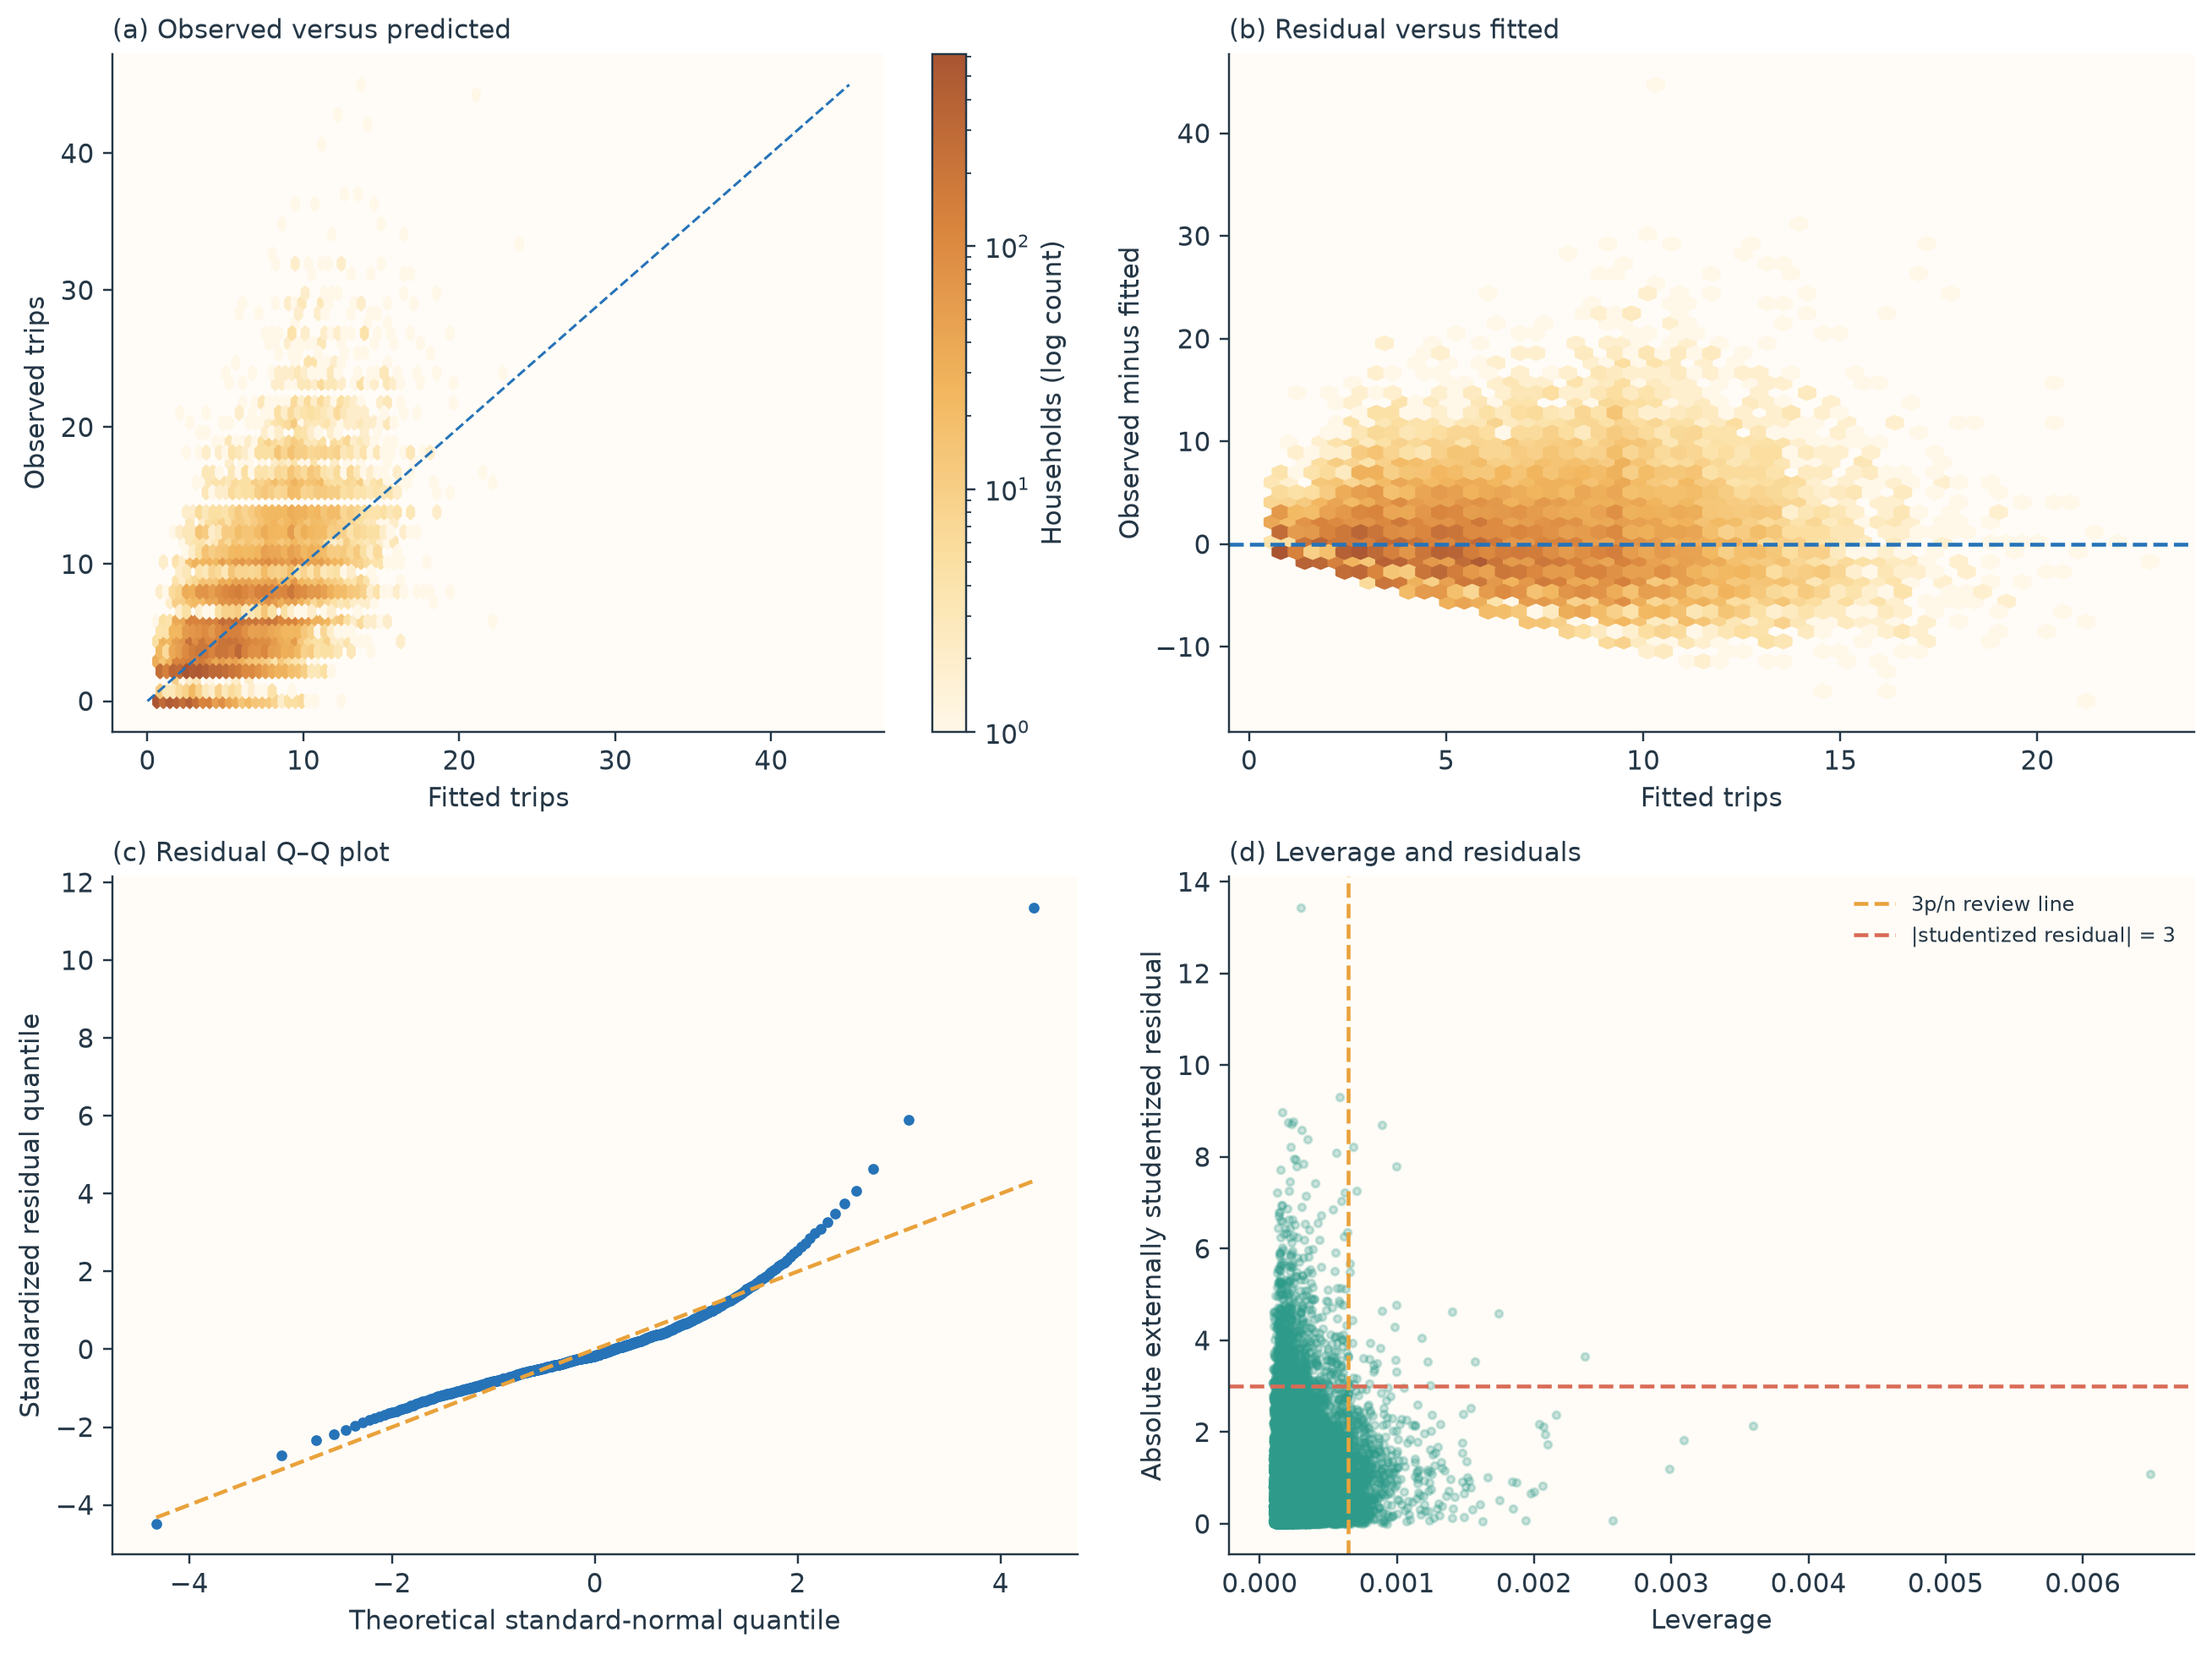

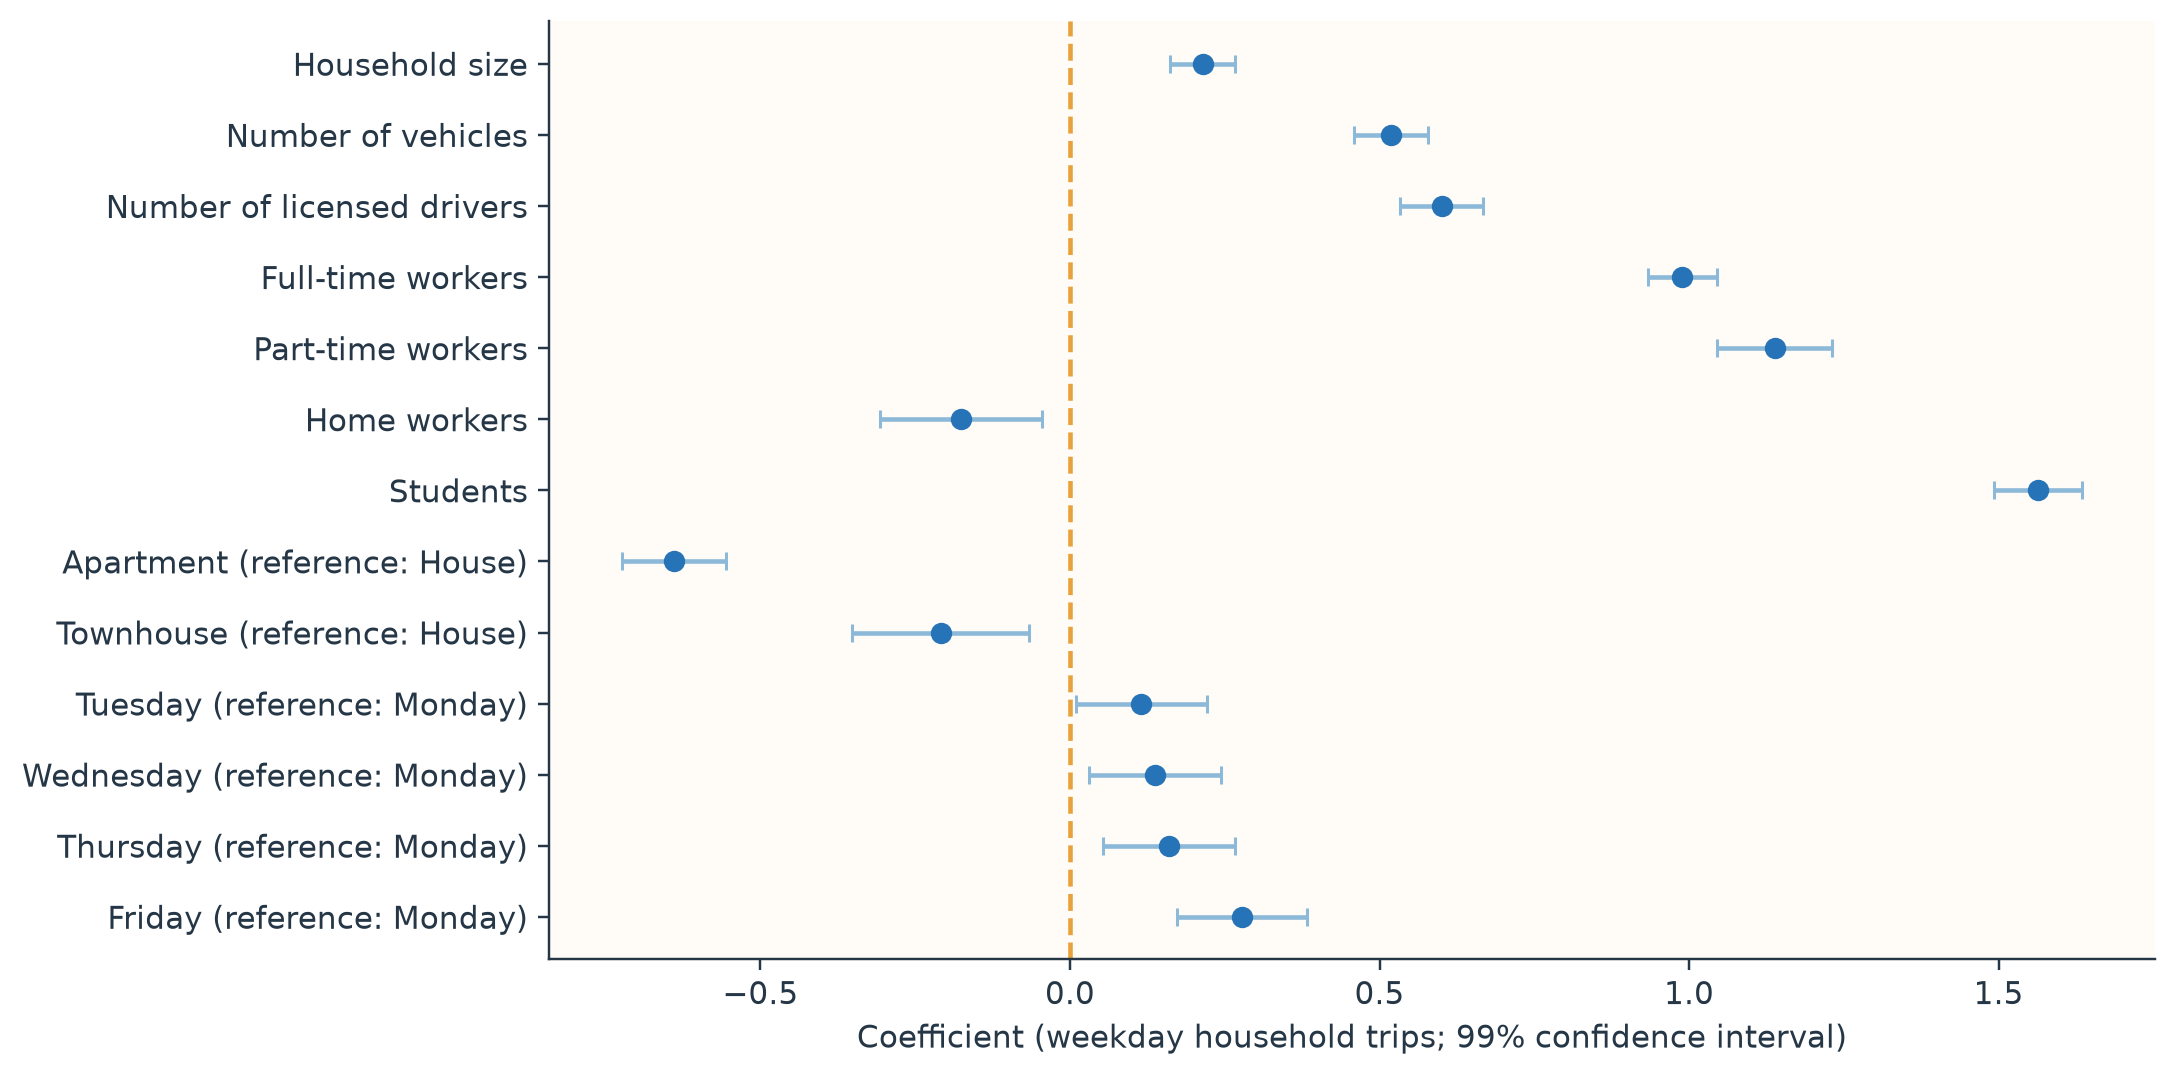

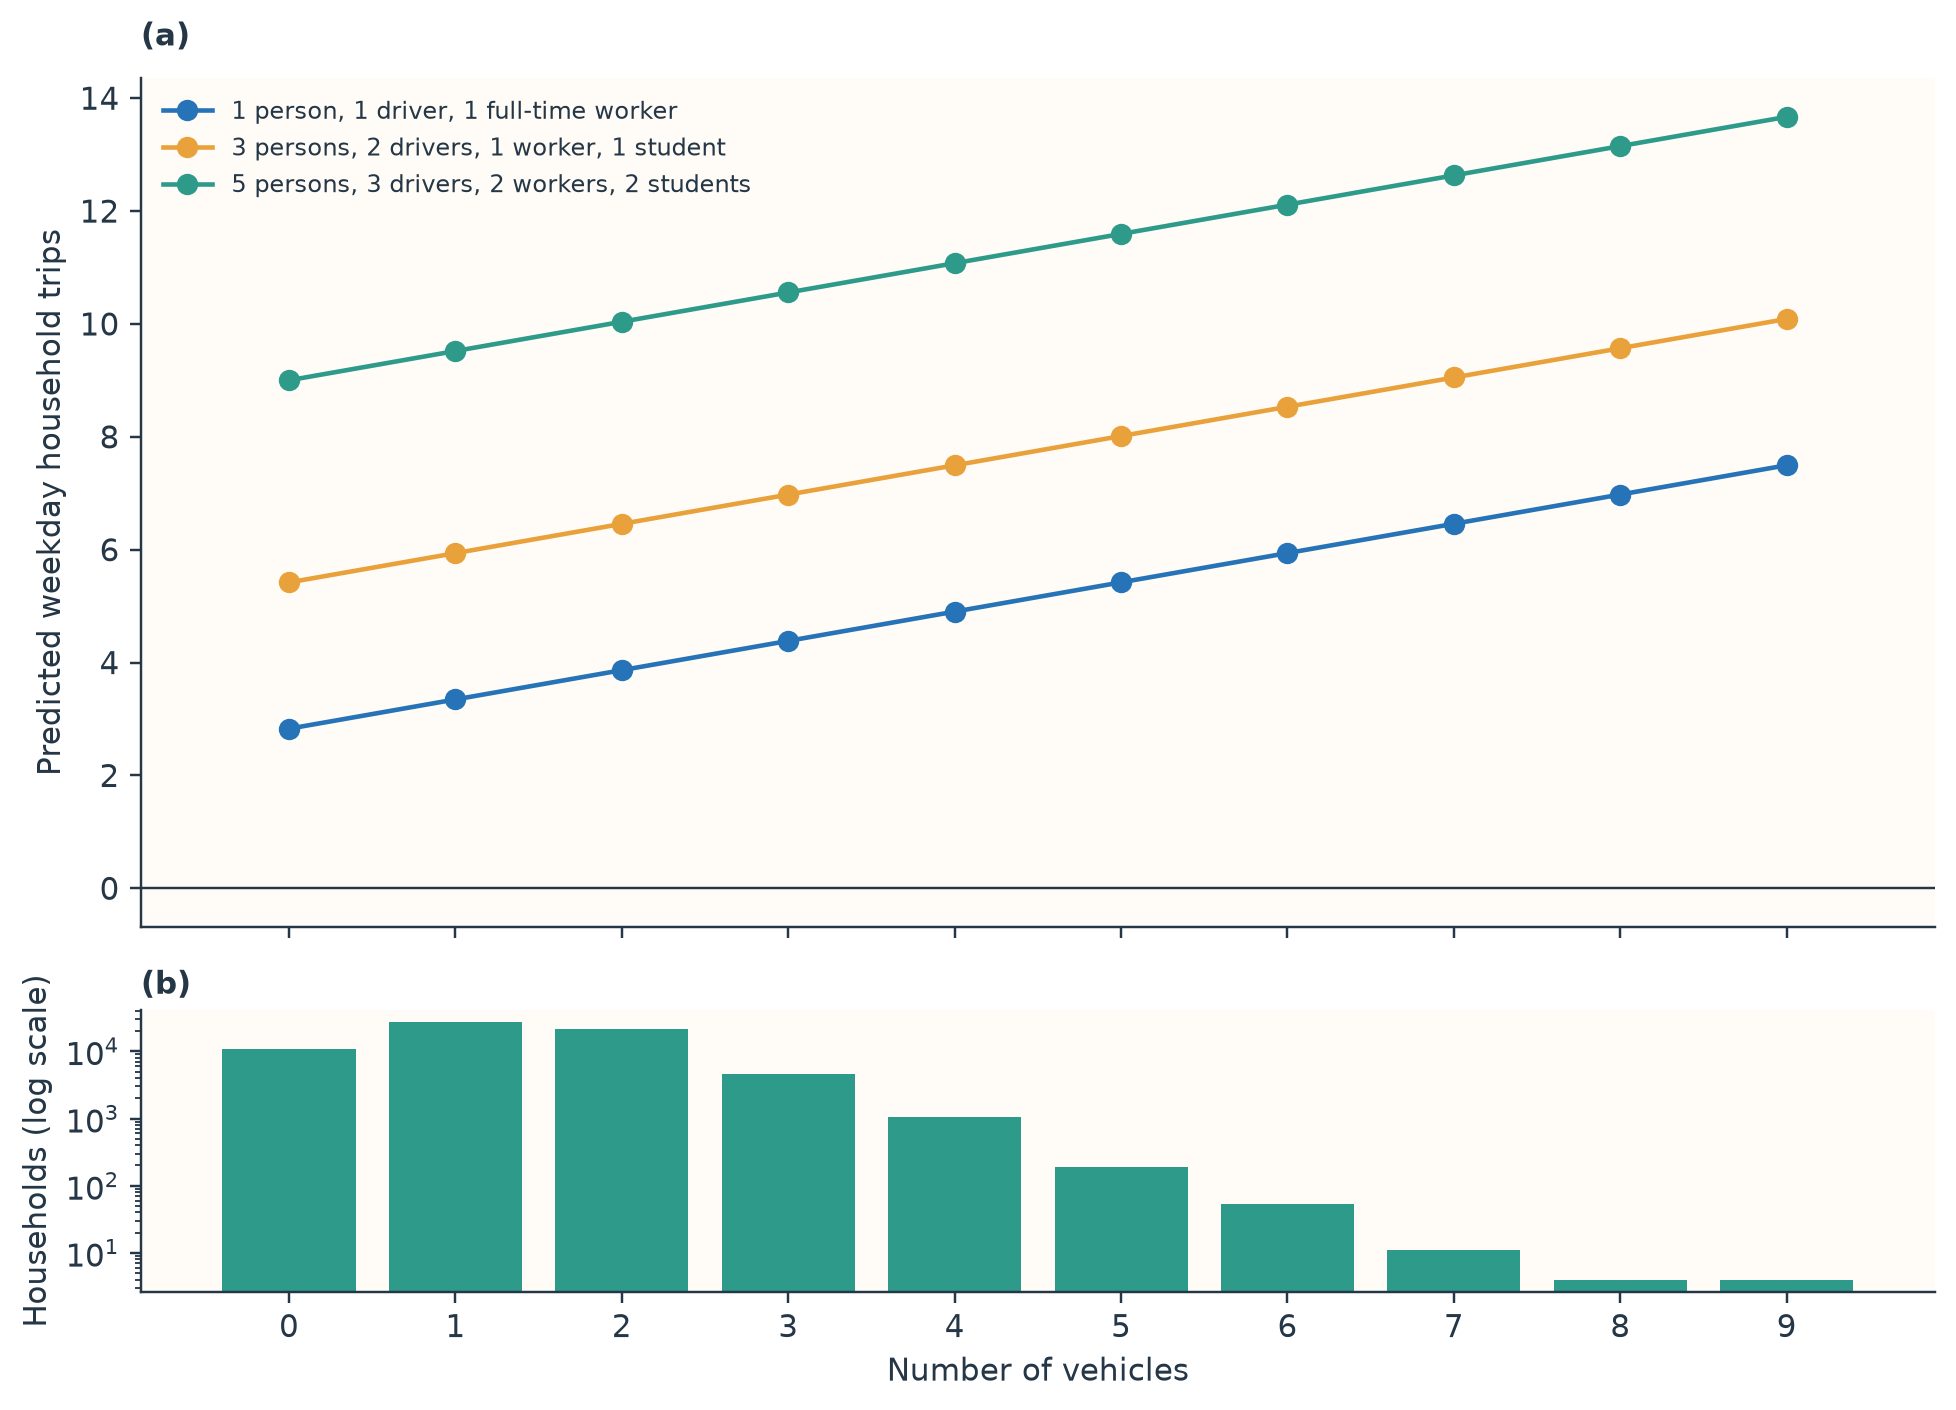

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
hb = axes[0, 0].hexbin(test_predicted, test_y, gridsize=55, mincnt=1, bins='log', cmap=WARM_HEAT)
limits = [min(0, predicted.min()), max(test_y.max(), test_predicted.max())]
axes[0, 0].plot(limits, limits, '--', color=BLUE, linewidth=1)
axes[0, 0].set(xlabel='Fitted trips', ylabel='Observed trips', title='Observed versus predicted')
fig.colorbar(hb, ax=axes[0, 0], label='Households (log count)')
axes[0, 1].hexbin(predicted, residual, gridsize=55, mincnt=1, bins='log', cmap=WARM_HEAT)
axes[0, 1].axhline(0, color=BLUE, linestyle='--')
axes[0, 1].set(xlabel='Fitted trips', ylabel='Observed minus fitted', title='Residual versus fitted')
probabilities = np.unique(np.r_[.5 / N, np.linspace(.001, .999, 499), 1 - .5 / N])
normal_quantiles = stats.norm.ppf(probabilities)
standardized_residual = residual / np.sqrt(selected_ols.mse_resid)
axes[1, 0].scatter(normal_quantiles, np.quantile(standardized_residual, probabilities), s=10, color=BLUE)
axes[1, 0].plot([normal_quantiles.min(), normal_quantiles.max()],
                [normal_quantiles.min(), normal_quantiles.max()], '--', color=ORANGE)
axes[1, 0].set(xlabel='Theoretical standard-normal quantile', ylabel='Standardized residual quantile',
               title='Residual Q–Q plot')
axes[1, 1].scatter(leverage, np.abs(studentized_external), s=8, alpha=.25, color=TEAL)
axes[1, 1].axvline(3 * P / N, color=ORANGE, linestyle='--', label='3p/n review line')
axes[1, 1].axhline(3, color=CORAL, linestyle='--', label='|studentized residual| = 3')
axes[1, 1].set(xlabel='Leverage', ylabel='Absolute externally studentized residual',
               title='Leverage and residuals')
axes[1, 1].legend(frameon=False, fontsize=8)
label_panels(axes)
fig.tight_layout()
save_figure(fig, 'MLR_01_fit_and_residuals')

fig, ax = plt.subplots(figsize=(10, max(5, .34 * (len(coefficients) - 1))))
plot_coefficients = coefficients.loc[coefficients['column'].ne('Intercept')].iloc[::-1]
positions = np.arange(len(plot_coefficients))
ax.errorbar(plot_coefficients['estimate'], positions,
    xerr=np.vstack([plot_coefficients['estimate'] - plot_coefficients['CI99_lower_zone_clustered'],
                    plot_coefficients['CI99_upper_zone_clustered'] - plot_coefficients['estimate']]),
    fmt='o', color=BLUE, ecolor='#8CB9D8', capsize=3)
ax.axvline(0, color=ORANGE, linestyle='--')
ax.set_yticks(positions, [coefficient_label(c) for c in plot_coefficients['column']])
ax.set(xlabel='Coefficient (weekday household trips; 99% confidence interval)')
fig.tight_layout()
save_figure(fig, 'MLR_02_coefficients')
# Conditional vehicle response for reference households; all other attributes are fixed.
vehicle_profiles = [
    ('1 person, 1 driver, 1 full-time worker', 1, 1, 1, 0),
    ('3 persons, 2 drivers, 1 worker, 1 student', 3, 2, 1, 1),
    ('5 persons, 3 drivers, 2 workers, 2 students', 5, 3, 2, 2),
]
vehicle_curve = pd.DataFrame([
    {'profile':label, 'persons':persons, 'licensed_drivers':drivers,
     'full_time_workers':workers, 'students':students, 'vehicles':vehicles}
    for label,persons,drivers,workers,students in vehicle_profiles
    for vehicles in range(10)
])
curve_features = pd.DataFrame(0.0, index=vehicle_curve.index, columns=features_all.columns)
curve_features['size_c'] = vehicle_curve['persons'] - 3
curve_features['vehicles_c'] = vehicle_curve['vehicles'] - 1
curve_features['drivers_c'] = vehicle_curve['licensed_drivers'] - 2
curve_features['full_time'] = vehicle_curve['full_time_workers']
curve_features['workers'] = vehicle_curve['full_time_workers']
curve_features['students'] = vehicle_curve['students']
curve_features['size_x_drivers'] = curve_features['size_c'] * curve_features['drivers_c']
curve_features['size_x_vehicles'] = curve_features['size_c'] * curve_features['vehicles_c']
curve_matrix, _ = build_matrix(chosen_effects, curve_features)
vehicle_curve['predicted_trips'] = curve_matrix @ np.asarray(selected_ols.params)
selected_coef = dict(zip(selected_columns, np.asarray(selected_ols.params)))
vehicle_support = train_trial['nvehicle'].value_counts()
vehicle_curve['training_households_at_vehicle_count'] = (
    vehicle_curve['vehicles'].map(vehicle_support).fillna(0).astype(int))
save_table('MLR18_vehicle_response', vehicle_curve)

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True,
                         gridspec_kw={'height_ratios':[3, 1]})
for profile, block in vehicle_curve.groupby('profile', sort=False):
    axes[0].plot(block['vehicles'], block['predicted_trips'], marker='o', label=profile)
axes[0].axhline(0, color=INK, linewidth=.8)
axes[0].set(ylabel='Predicted weekday household trips')
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar(range(10), vehicle_support.reindex(range(10), fill_value=0), color=TEAL)
axes[1].set(yscale='log', xticks=range(10), xlabel='Number of vehicles',
            ylabel='Households (log scale)')
label_panels(axes)
fig.tight_layout()
save_figure(fig, 'MLR_04_vehicle_response')

,grouping,level,n,observed_mean_trips,predicted_mean_trips,MAE_test,RMSE_test,mean_prediction_error_pred_minus_obs,negative_predictions_n
0,Household size (5+),2,8490,4.3624,4.2365,2.1475,2.8440,-0.1259,0
1,Household size (5+),3,5308,6.3306,6.3817,2.4953,3.3368,0.0511,0
2,Household size (5+),1,5763,2.0106,2.2121,1.3096,1.6966,0.2016,0
3,Household size (5+),4,5278,8.2958,8.2464,3.1265,4.1895,-0.0494,0
4,Household size (5+),5+,3139,10.1634,10.2872,3.7927,5.0615,0.1237,0
5,Vehicles (4+),2,9322,7.3585,7.2219,2.9074,3.9604,-0.1366,0
6,Vehicles (4+),1,11485,4.8458,4.8234,2.2400,3.0664,-0.0224,0
7,Vehicles (4+),0,4583,2.3227,2.5799,1.3435,1.7671,0.2572,0
8,Vehicles (4+),3,2039,8.6587,8.8881,3.1790,4.2318,0.2294,0
9,Vehicles (4+),4+,549,9.7723,10.4562,3.5746,4.7513,0.6839,0


,evaluation,zones,MAE,RMSE,mean_prediction_error_pred_minus_obs,status
0,Sample zone totals,1081,14.4589,20.3315,0.4547,Reserved-test zone agreement
1,Expansion-weighted zone totals,1081,279.6017,396.1838,10.7359,Reserved-test zone agreement


,evaluation,observed_mean,predicted_mean,MAE,RMSE,mean_prediction_error
0,Unweighted reserved-test households,5.6443,5.6618,2.4102,3.3683,0.0176
1,Expansion-weighted reserved-test households; coefficients still unweighted OLS,5.6430,5.6644,2.4081,3.3665,0.0214


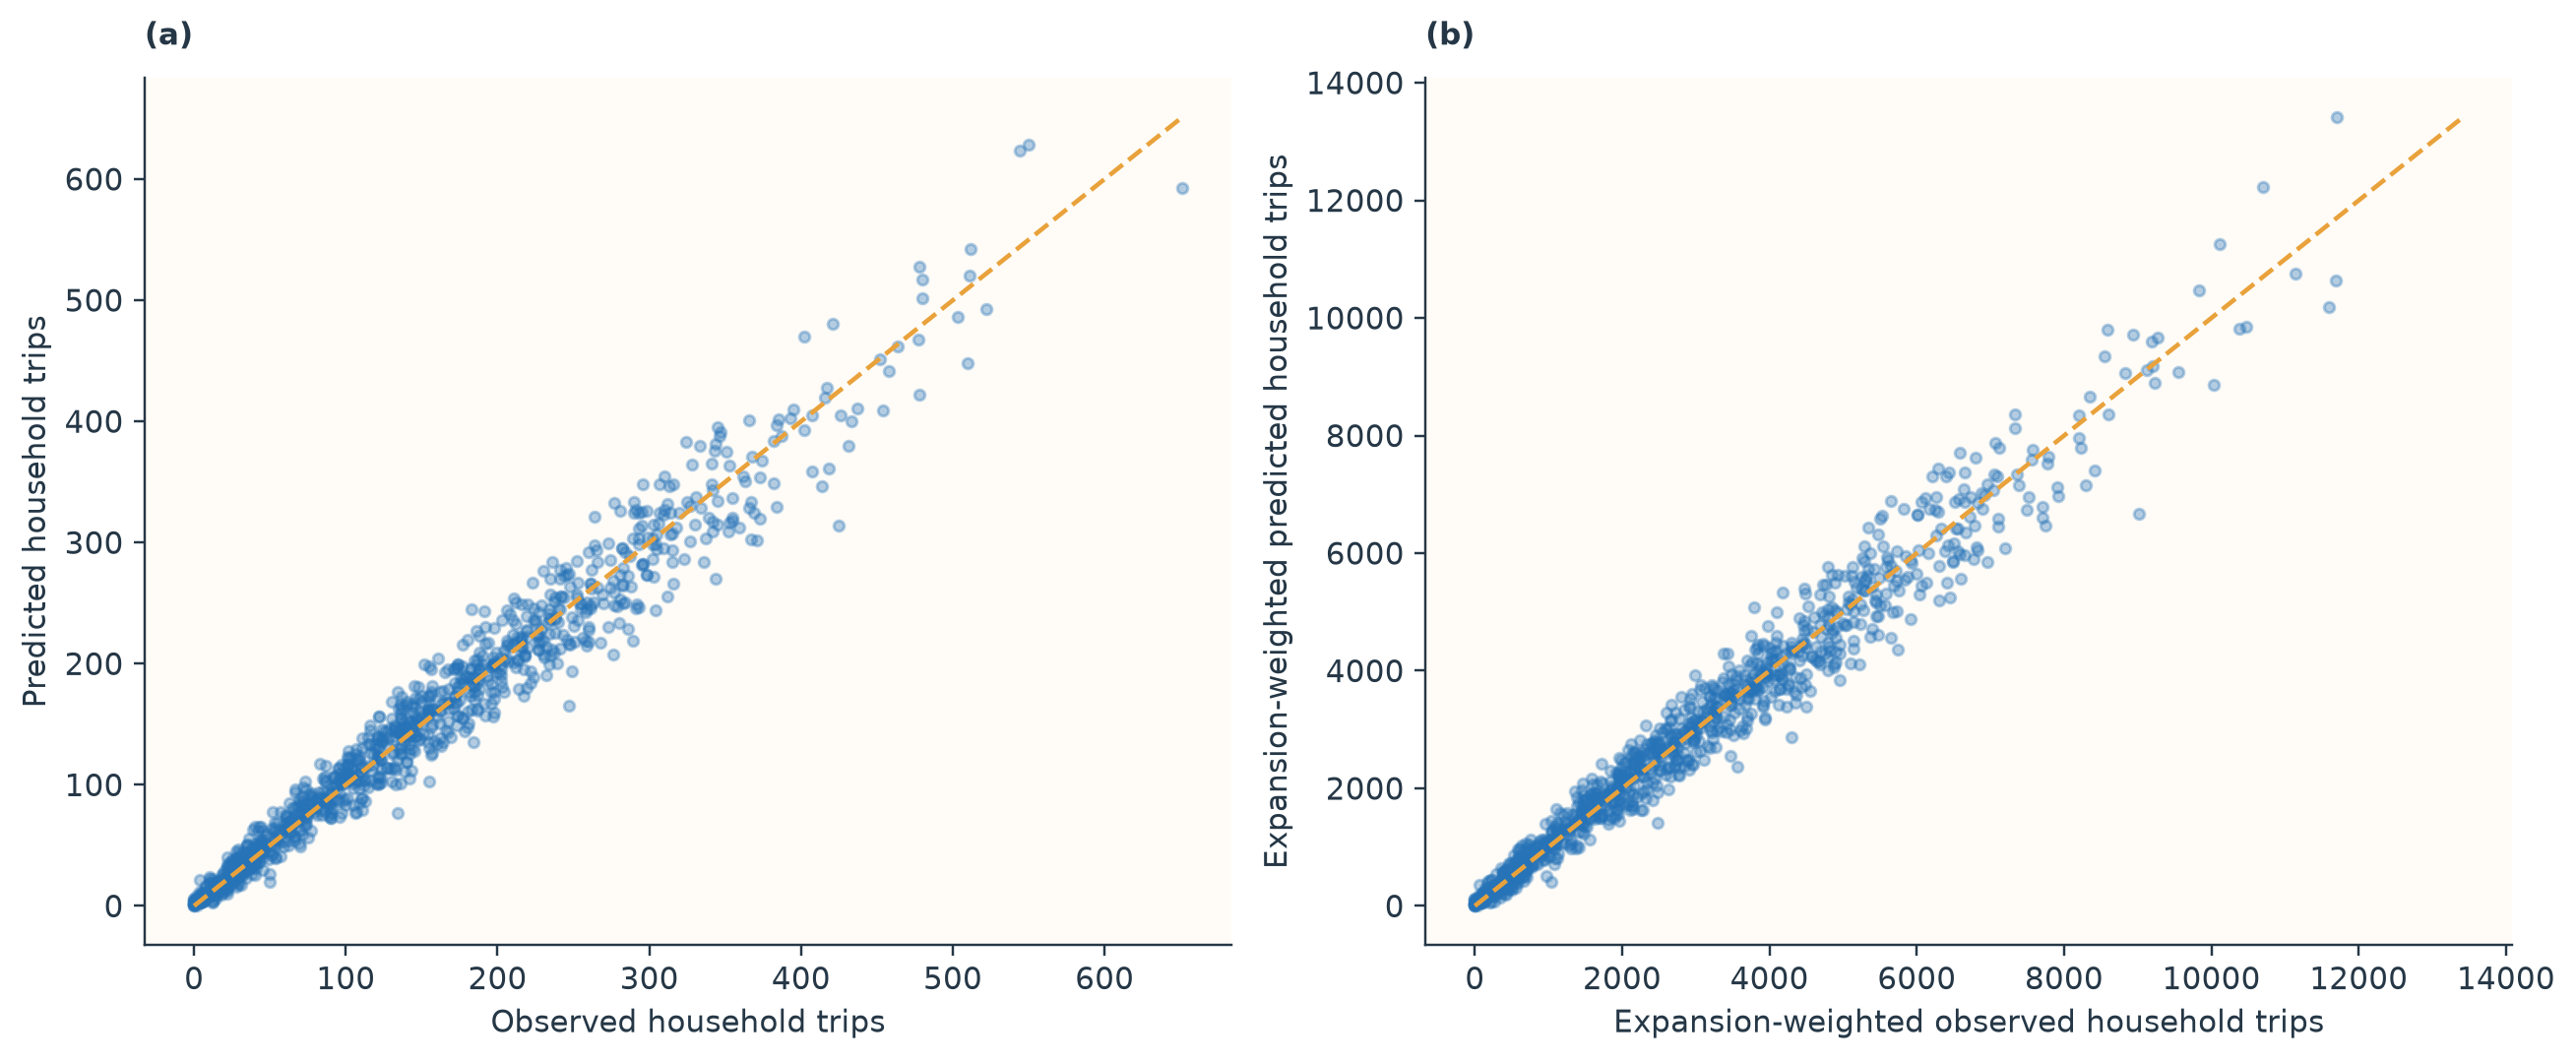

In [10]:
group_rows = []
group_definitions = {
    'Household size (5+)': test_trial['nperson'].clip(upper=5).astype(str).where(test_trial['nperson'].lt(5), '5+'),
    'Vehicles (4+)': test_trial['nvehicle'].clip(upper=4).astype(str).where(test_trial['nvehicle'].lt(4), '4+'),
    'Dwelling': test_trial['dwelling'], 'Weekday': test_trial['weekday'], 'Region': test_trial['region'],
}
for variable, grouping in group_definitions.items():
    for level in grouping.unique():
        mask = grouping.eq(level).to_numpy()
        error = test_predicted[mask] - test_y[mask]
        group_rows.append({'grouping': variable, 'level': str(level), 'n': int(mask.sum()),
            'observed_mean_trips': test_y[mask].mean(), 'predicted_mean_trips': test_predicted[mask].mean(),
            'MAE_test': np.abs(error).mean(), 'RMSE_test': np.sqrt(np.mean(error ** 2)),
            'mean_prediction_error_pred_minus_obs': error.mean(),
            'negative_predictions_n': int((test_predicted[mask] < 0).sum())})
group_performance = save_table('MLR14_household_group_performance', pd.DataFrame(group_rows))
zone_data = pd.DataFrame({'zone': test_zones, 'observed': test_y, 'predicted': test_predicted,
    'expanded_observed': test_weights * test_y, 'expanded_predicted': test_weights * test_predicted,
    'expansion_weight': test_weights})
zone_performance = zone_data.groupby('zone').agg(
    households=('observed', 'size'), observed_sample_trips=('observed', 'sum'),
    predicted_sample_trips=('predicted', 'sum'), expanded_observed_trips=('expanded_observed', 'sum'),
    expanded_predicted_trips=('expanded_predicted', 'sum'), expanded_households=('expansion_weight', 'sum')).reset_index()
zone_performance['sample_prediction_error'] = zone_performance['predicted_sample_trips'] - zone_performance['observed_sample_trips']
zone_performance['expanded_prediction_error'] = zone_performance['expanded_predicted_trips'] - zone_performance['expanded_observed_trips']
save_table('MLR15_zone_performance', zone_performance)
zone_summary_rows = []
for label, col in [('Sample zone totals', 'sample_prediction_error'), ('Expansion-weighted zone totals', 'expanded_prediction_error')]:
    error = zone_performance[col].to_numpy()
    zone_summary_rows.append({'evaluation': label, 'zones': len(error),
        'MAE': np.abs(error).mean(), 'RMSE': np.sqrt(np.mean(error ** 2)),
        'mean_prediction_error_pred_minus_obs': error.mean(), 'status': 'Reserved-test zone agreement'})
zone_summary = save_table('MLR16_zone_summary', pd.DataFrame(zone_summary_rows))
overall_weight_sensitivity = save_table('MLR17_expansion_weighted_evaluation', pd.DataFrame([
    {'evaluation': 'Unweighted reserved-test households', 'observed_mean': test_y.mean(),
     'predicted_mean': test_predicted.mean(), 'MAE': np.abs(test_error).mean(),
     'RMSE': np.sqrt(np.mean(test_error ** 2)), 'mean_prediction_error': test_error.mean()},
    {'evaluation': 'Expansion-weighted reserved-test households; coefficients still unweighted OLS',
     'observed_mean': np.average(test_y, weights=test_weights),
     'predicted_mean': np.average(test_predicted, weights=test_weights),
     'MAE': np.average(np.abs(test_error), weights=test_weights),
     'RMSE': np.sqrt(np.average(test_error ** 2, weights=test_weights)),
     'mean_prediction_error': np.average(test_error, weights=test_weights)},
]))
display(group_performance.round(4))
display(zone_summary.round(4))
display(overall_weight_sensitivity.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, observed_col, predicted_col, title in [
    (axes[0], 'observed_sample_trips', 'predicted_sample_trips', 'Sample trip totals'),
    (axes[1], 'expanded_observed_trips', 'expanded_predicted_trips', 'Expansion-weighted trip totals')]:
    ax.scatter(zone_performance[observed_col], zone_performance[predicted_col], s=12, alpha=.35, color=BLUE)
    largest = max(zone_performance[observed_col].max(), zone_performance[predicted_col].max())
    ax.plot([0, largest], [0, largest], '--', color=ORANGE)
    ax.set(xlabel='Observed household trips' if ax is axes[0] else 'Expansion-weighted observed household trips',
           ylabel='Predicted household trips' if ax is axes[0] else 'Expansion-weighted predicted household trips')
label_panels(axes)
fig.tight_layout()
save_figure(fig, 'MLR_03_zone_agreement')

In [11]:
def markdown_table(frame):
    frame = frame.copy()
    for col in frame.columns:
        if col in ['p_clustered', 'p_classical', 'p_zone_clustered']:
            frame[col] = frame[col].map(format_pvalue)
        elif pd.api.types.is_numeric_dtype(frame[col]):
            frame[col] = frame[col].map(lambda value: '' if pd.isna(value) else f'{value:.7g}')
    frame = frame.astype(object).where(frame.notna(), '')
    lines = ['| ' + ' | '.join(map(str, frame.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    lines += ['| ' + ' | '.join(str(v).replace('|', '/').replace('\n', ' ') for v in row) + ' |'
              for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines)

chosen_stats = chosen_info['stats']
chosen_benchmark = benchmarks.loc[benchmarks['model'].eq('Selected alternative model')].iloc[0]
additive_benchmark = benchmarks.loc[benchmarks['model'].eq('Best additive linear model')].iloc[0]
simple_benchmark = benchmarks.loc[benchmarks['model'].eq('Simple four-predictor model')].iloc[0]
simple_equation = 'Predicted trips = ' + ' '.join(
    (f'{row.estimate:+.5f} * {row.column}' if row.column != 'Intercept' else f'{row.estimate:.5f}')
    for row in simple_coefficients.itertuples())

equation = 'Predicted trips = ' + ' '.join(
    (f'{row.estimate:+.5f} * {row.column}' if row.column != 'Intercept' else f'{row.estimate:.5f}')
    for row in coefficients.itertuples())

derived_rows = []
def derive(quantity, value, unit, reference, sample, source):
    derived_rows.append(dict(quantity=quantity, value=value, unit=unit,
        reference_or_denominator=reference, sample=sample, source=source))
def derived_markdown(frame):
    lines = ['| Quantity | Value | Unit | Reference / denominator | Sample | Source / formula |',
             '| --- | ---: | --- | --- | --- | --- |']
    for r in frame.itertuples(index=False):
        value = f'{r.value:.7g}' if isinstance(r.value, (float, int, np.number)) else str(r.value)
        lines.append(f'| {r.quantity} | {value} | {r.unit} | {r.reference_or_denominator} | {r.sample} | {r.source} |')
    return '\n'.join(lines)

for sample,frame,pred in [('training',train_trial,predicted),('test',test_trial,test_predicted)]:
    outcome=frame.nhhldtrip
    for label,value,unit in [('n',len(frame),'households'),('mean',outcome.mean(),'trips'),('SD',outcome.std(ddof=1),'trips'),
        ('zero count',int(outcome.eq(0).sum()),'households'),('zero share',outcome.eq(0).mean(),'proportion')]:
        derive(f'Outcome {label}',value,unit,f'{sample} households',sample,'nhhldtrip; sample SD uses ddof=1')
    neg=frame.loc[pred<0]
    derive('Negative prediction count',len(neg),'households',sample,sample,'Selected model: prediction < 0')
    derive('Minimum prediction',float(np.min(pred)),'trips',sample,sample,'Selected prediction minimum across all households')
    derive('Minimum negative prediction',float(np.min(pred[pred<0])) if len(neg) else np.nan,'trips','negative predictions',sample,'Minimum restricted to prediction < 0; NA if none')
    for stat in ['min','max']:
        derive(f'Negative prediction vehicle {stat}',getattr(neg.nvehicle,stat)() if len(neg) else np.nan,'vehicles','negative predictions',sample,'nvehicle among negative predictions; NA if none')
negative_predictions=pd.concat([f.assign(sample=label).loc[f.predicted_trips<0,
    ['sample','hnum','nperson','nvehicle','nlicence','nhhldtrip','predicted_trips']]
    for label,f in [('training',predictions),('test',test_predictions)]],ignore_index=True)
save_table('Negative_predictions',negative_predictions)
rank1,rank2=all_candidates.iloc[0],all_candidates.iloc[1]
derive('BIC rank 2 minus rank 1',rank2.bic-rank1.bic,'BIC','rank 1','training','MLR04: BIC[2] - BIC[1]')
derive('Rank 2 omits from rank 1',', '.join(sorted(set(rank1.effects.split(' + '))-set(rank2.effects.split(' + ')))) or 'none','effects','rank 1','training','Set difference of candidate effects')
for label,value in [('BIC rank',best_additive_row.bic_rank),('BIC gap to rank 1',best_additive_row.bic-rank1.bic),('R squared',best_additive_row.r_squared)]:
    derive(f'Best additive {label}',value,'rank' if label=='BIC rank' else 'R squared' if label=='R squared' else 'BIC','rank 1 for gap','training','MLR04: lowest BIC without interactions')
for persons in range(1,6):
    for label,main,interaction in [('Licence-holder','drivers_c','size_x_drivers'),('Vehicle','vehicles_c','size_x_vehicles')]:
        derive(f'{label} slope; persons={persons}',selected_coef.get(main,0)+selected_coef.get(interaction,0)*(persons-3),
            'trips per unit',f'persons={persons}; other predictors fixed','training',f'{main} + {interaction} * (persons - 3); absent effects = 0')
regional=[]
means=train_trial.groupby('region').nhhldtrip.mean()
for region in ['Durham','York','Peel']:
    raw_diff=means[region]-means['Toronto'];adjusted=selected_coef.get('region_'+region,0)
    regional.append(dict(region=region,reference='Toronto',unadjusted_difference=raw_diff,adjusted_difference=adjusted))
    for label,value in [('Unadjusted',raw_diff),('Adjusted',adjusted)]:
        derive(f'{label} {region} minus Toronto',value,'trips','Toronto','training',
               'Regional means difference' if label=='Unadjusted' else 'Selected region coefficient; zero if region omitted')
save_table('Regional_differences',pd.DataFrame(regional))
derived_mlr=save_table('Derived_MLR',pd.DataFrame(derived_rows))
assert len(predictions)==N and len(test_predictions)==N_TEST
assert len(negative_predictions)==int((predicted<0).sum()+(test_predicted<0).sum())
print('Derived quantities');display(derived_mlr);display(negative_predictions)

report = f'''# Multiple linear regression: simple and alternative specifications

## Sample and split

This notebook regenerates the common split from sorted source household IDs with NumPy PCG64 seed {SPLIT_SEED} and {TEST_FRACTION:.0%} assigned to test before exclusions. It verifies exact agreement with the split saved by EDA. It applies the previously chosen vehicle >=10 and unknown-dwelling exclusions to both partitions. The eligible sample is {len(trial):,} households: {N:,} training and {N_TEST:,} reserved test. Zero-trip households are retained. The source workbook remains unchanged.

## Simple starting specification

The prespecified starting model uses household persons (`nperson`), vehicles (`nvehicle`), full-time workers (`nempft`), and students (`nstudent`). These four predictors were fixed before the broader search. Its fitted equation is:

{simple_equation}

Here `size_c = nperson - 3` and `vehicles_c = nvehicle - 1`. The simple model has training R-squared {simple_ols.rsquared:.4f}, reserved-test RMSE {simple_benchmark['test_rmse']:.4f}, and reserved-test MAE {simple_benchmark['test_mae']:.4f}. Its coefficients and exploratory 99% zone-clustered intervals are below.

{markdown_table(simple_coefficients)}

The transportation basis and interpretation limits for all candidate effects are in [feature_rationale.md](feature_rationale.md).

## Model search

The declared effect space contains household size, vehicles, licensed drivers, separate or total employment counts, home workers, students, dwelling type, weekday, region, optional size-by-driver and size-by-vehicle interactions. Every main effect, including household size, is optional. Categorical levels move as whole factors, workers cannot accompany separate employment counts, and hierarchy is enforced. All {len(all_candidates):,} valid effect subsets were scored on training data by Gaussian OLS AIC and BIC. Interactions are optional predictors in a model that remains linear in coefficients. The squared terms were removed after the first evaluation because their parabolic form made predicted trips fall at high vehicle counts and produced negative predictions.

The primary choice is the lowest-BIC valid subset whose removable whole effects have zone-clustered p<0.01. It has BIC rank {chosen_rank} among all scored models. {len(screened_models)} BIC-ranked model(s) required clustered screening. AIC/BIC are working unweighted Gaussian criteria. The 99% clustered intervals below are exploratory after selection, and none is claimed to have selection-adjusted coverage.

## Selected equation and performance

Retained effects: {', '.join(chosen_effects)}.

{equation}\n\nHere `size_c = size - 3`, `vehicles_c = vehicles - 1`, and `drivers_c = licensed drivers - 2`; interaction columns use these centered values. The model has {chosen_stats['parameters']} coefficients including its intercept. Training R-squared is {chosen_stats['r_squared']:.4f}. Training RMSE is {chosen_stats['rmse_in_sample']:.4f}; reserved-test RMSE is {chosen_benchmark['test_rmse']:.4f} and reserved-test MAE is {chosen_benchmark['test_mae']:.4f}. These are household trip-count errors, not causal effects. The best additive linear model, which contains no interactions, has reserved-test RMSE {additive_benchmark['test_rmse']:.4f}.\n\n{markdown_table(benchmarks.round(5))}

The centered main coefficients describe conditional slopes at three persons, one vehicle, and two licensed drivers. When retained, interactions allow the licence-holder and vehicle slopes to vary with household size. [The vehicle-response figure](figures/MLR_04_vehicle_response.png) uses the revised model. The `Derived_MLR` sheet reports these slopes, and `Negative_predictions` lists every negative prediction without clipping.

## Derived quantities

{derived_markdown(derived_mlr)}

## Candidate leaders and coefficient uncertainty

{markdown_table(comparison[['bic_rank', 'aic_rank', 'effects', 'parameters', 'aic', 'bic', 'selected_alternative']].head(20).round(3))}

{markdown_table(selected_effect_tests)}

{markdown_table(coefficients.drop(columns='interval_status'))}

## Diagnostics and zone evaluation

Training residual skewness is {stats.skew(residual, bias=False):.3f} and excess kurtosis is {stats.kurtosis(residual, bias=False):.3f}. {int((np.abs(studentized_external) > 3).sum()):,} training records have absolute externally studentized residuals above 3; these are review markers and are retained. There are {int((test_predicted < 0).sum()):,} negative reserved-test predictions. Count-outcome and survey-weight limitations remain relevant. The data guide records trips only for persons aged 11+, while the student count includes assumed students aged 6-10.

{markdown_table(zone_summary.round(4))}

{markdown_table(overall_weight_sensitivity.round(4))}

Traffic-zone sample and expanded totals use the same reserved-test records. Expansion factors are applied consistently to observed and predicted totals. The expanded sums cover the test subset and are not full-population zone totals. Coefficients are unweighted OLS. The cross-classification comparison uses the same eligible IDs and seeded split.

## Reproduction and files

Run `MLR_regression.ipynb` top to bottom from the project root with the requirements in requirements.txt. `final_outputs/MLR_regression/MLR_regression_results.xlsx` contains the full candidate list, coefficient and diagnostic tables, the vehicle-response table, working sample, exclusions, and both prediction sets. `selected_MLR_regression_model.json` records the equation, selection settings, source hash, and split hashes. Figures are saved in `final_outputs/MLR_regression/figures`.

Source workbook SHA256: {SOURCE_SHA256}

Training ID SHA256: {row_id_hash}

Test ID SHA256: {test_row_id_hash}
'''
(OUTPUT / 'MLR_regression_results.md').write_text(report, encoding='utf-8')

workbook_path = OUTPUT / 'MLR_regression_results.xlsx'
sheet_names = set()
with pd.ExcelWriter(workbook_path, engine='openpyxl') as writer:
    for name, frame in WORKBOOK_SHEETS.items():
        sheet = name[:31]
        assert sheet not in sheet_names, f'Duplicate Excel sheet name: {sheet}'
        sheet_names.add(sheet)
        frame.to_excel(writer, sheet_name=sheet, index=False)
        writer.sheets[sheet].freeze_panes = 'A2'
        writer.sheets[sheet].auto_filter.ref = writer.sheets[sheet].dimensions

assert hashlib.sha256(WORKBOOK.read_bytes()).hexdigest() == SOURCE_SHA256
assert np.array_equal(pd.util.hash_pandas_object(raw, index=True), raw_fingerprint)
assert len(train_trial) + len(test_trial) == len(trial)
assert set(train_trial['hnum']).isdisjoint(set(test_trial['hnum']))
assert np.isclose(zone_performance['observed_sample_trips'].sum(), test_y.sum())
assert np.isclose(zone_performance['predicted_sample_trips'].sum(), test_predicted.sum())
assert np.isclose(zone_performance['expanded_observed_trips'].sum(), np.dot(test_weights, test_y))
assert np.isclose(zone_performance['expanded_predicted_trips'].sum(), np.dot(test_weights, test_predicted))
assert np.allclose(test_matrix @ selected_ols.params, test_predicted)
print(f'Saved {workbook_path} with {len(WORKBOOK_SHEETS)} sheets.')
print('Source, split, training-only selection, and reserved-test aggregation checks passed.')
display(comparison.loc[comparison['selected_alternative'],
    ['bic_rank', 'aic_rank', 'effects', 'parameters', 'aic', 'bic']])

Derived quantities


,quantity,value,unit,reference_or_denominator,sample,source
0,Outcome n,65287,households,training households,training,nhhldtrip; sample SD uses ddof=1
1,Outcome mean,5.642364,trips,training households,training,nhhldtrip; sample SD uses ddof=1
2,Outcome SD,4.548931,trips,training households,training,nhhldtrip; sample SD uses ddof=1
3,Outcome zero count,7274,households,training households,training,nhhldtrip; sample SD uses ddof=1
4,Outcome zero share,0.111416,proportion,training households,training,nhhldtrip; sample SD uses ddof=1
5,Negative prediction count,0,households,training,training,Selected model: prediction < 0
6,Minimum prediction,0.59918,trips,training,training,Selected prediction minimum across all households
7,Minimum negative prediction,NaN,trips,negative predictions,training,Minimum restricted to prediction < 0; NA if none
8,Negative prediction vehicle min,NaN,vehicles,negative predictions,training,nvehicle among negative predictions; NA if none
9,Negative prediction vehicle max,NaN,vehicles,negative predictions,training,nvehicle among negative predictions; NA if none


,sample,hnum,nperson,nvehicle,nlicence,nhhldtrip,predicted_trips


Saved /home/mst_lab/Desktop/king/Classwork/TRP630/Term_paper/trp631termpaper/final_outputs/MLR_regression/MLR_regression_results.xlsx with 25 sheets.
Source, split, training-only selection, and reserved-test aggregation checks passed.


,bic_rank,aic_rank,effects,parameters,aic,bic
0,1,14,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday,14,342498.305516,342625.517191
